### Simple environment
using random jamming, single action instead of dual for simplicity (1 action , identified by freq * power)


In [ ]:
import gymnasium as gym
import numpy as np
import random as random
from gymnasium import spaces
from gymnasium.envs.registration import register     #name the env
from gymnasium.utils.env_checker import check_env   #check if the env follows the gym API   
import matplotlib.pyplot as plt
from IPython.display import display
import time

#make the name of the env
register(
    id='AntiJammingEnv-v0',                         #name of the env when we instatiate
    # entry_point="simplenv.ipynb:AntiJammingEnv",   #module name:class name
    entry_point= lambda **kwargs: AntiJammingEnv(**kwargs),  #if the class is in the same file, we can use lambda
)


class AntiJammingEnv(gym.Env):
    # used to render the env
    metadata = {"render_modes": ["human"], "render_fps": 10}


    def __init__(self, num_freqs=22, num_powers=50, num_of_jammers=7, jammer_type="random", render_mode=None):
        super().__init__()
        self.num_freqs = num_freqs
        self.num_powers = num_powers
        self.jammer_type = jammer_type          #random in this env
        self.num_of_jammers = num_of_jammers    # 7 random jammers
        self.prev_freq = None                   #need for freq switching penalty
        self.state = None                 # current observation (PSD vector)
        self._sweep_step = 1             # how many bins to move per step for sweeping jammer

        #all rendering related variables
        self.render_mode = render_mode
        self._fig = None
        self._ax = None
        self._jam_bars = None
        self._agent_line = None
        self._power_text = None
        self._last_action = None
        self._last_reward = None
        self.agent_marker = None
        self._display_handle = None


        # Define action space (freq × power combinations)
        # 22 * 50 = 1100 discrete actions (0..1099)
        # too many actions for DQN, but OK for policy gradient methods
        self.action_space = spaces.Discrete(num_freqs * num_powers)

        # State = PSD (vector of size num_freqs)
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(num_freqs,), dtype=np.float32
        )

        #self.rng = random number generator
        self.rng = np.random.default_rng()

        # Internal jammer state & dynamics parameters
        self._jam_idxs = []             # indices of the currently jammed frequency bins


    def _build_state_from_jammer(self):
        """
        Construct the PSD observation vector given the *current* jammers indecies.
        - Background noise is simulated as small random values (0..0.1).
        - Multiple freqs (self._jam_idxs) is set to 1.0 to represent the jammer’s power.
        
        This function is used in both `reset()` and `step()` so that
        the observation is always generated consistently.
        """
        s = self.rng.random(self.num_freqs) * 0.1   # background noise
        if len(self._jam_idxs) == 0:                   # if no jammer index yet, pick a random one
            self._jam_idxs = self.np_random.choice(range(self.num_freqs), size=self.num_of_jammers, replace=False).tolist()
        for i in self._jam_idxs:
            s[i] = 1.0
    
        return s.astype(np.float32)
    
    

    def _advance_jammer(self):
        """
        Update the jammer index based on jammer_type dynamics:
        - fixed: jammer never moves
        - sweeping: jammer shifts to the next bin each step
        - random: jammer picks a new random bin every step
        """

        jt = self.jammer_type.lower()
        if jt == "fixed":
            pass  # jammer stays in the same bin forever

        elif jt == "sweeping":
            for i in range(len(self._jam_idxs)):
                #modulo to wrap around (23 -> 1 for example)
                self._jam_idxs[i] = (self._jam_idxs[i] + self._sweep_step) % self.num_freqs

        else:  # default "random"
            for i in range(len(self._jam_idxs)):
                self._jam_idxs[i] = int(self.rng.integers(0, self.num_freqs))



    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        # Initialize jammer index and build the first observation
        # used self.np_random that apparently got initted by super().reset(seed=seed)
        self._jam_idxs = self.np_random.choice(self.num_freqs, size=self.num_of_jammers, replace=False).tolist()
        self.state = self._build_state_from_jammer()

        self.prev_freq = None
        info = {}

        #rendering related book-keeping
        self._last_action = None
        self._last_reward = None

        return self.state.astype(np.float32), info
    



    def step(self, action):
            """
            One-slot delay logic:
            - Agent picked `action` using observation s_k (= self._last_state).
            - Environment first advances jammer to unseen slot k+1 and measures s_{k+1}.
            - Reward is computed against s_{k+1} (the actual slot you just transmitted in).
            - Next observation returned to agent is s_{k+1}.
            """
            # Decode (freq, power)
            freq = action // self.num_powers
            power = action % self.num_powers + 1  # 1..num_powers
            # Map integer range [1, 50] to float range [0.1, 1.5]
            min_power = 0.1
            max_power = 0.9         # so that power is scaled. jamming caps at 1.0
                                    # old method kept power at 50. so agent didn't care about jammer
            power = min_power + (power - 1) * (max_power - min_power) / 49

            # === Move to *new* (unseen) slot and measure PSD_{k+1} ===
            self._advance_jammer()
            curr_psd = self._build_state_from_jammer()   # s_{k+1}

            # --- Compute reward using the *current* slot conditions (which were not observed before acting) ---
            noise_at_chosen = curr_psd[freq]
            snr = power / (noise_at_chosen + 1e-6)
            crc_success = 1 if snr > 1.5 else 0

            # Switching penalty (compare with last used freq)
            penalty = 0.0
            if self.prev_freq is not None and self.prev_freq != freq:
                penalty = -2.0

            # Reward 
            
            # why do we need this? because in the paper,
            # reward is based on SNR wrt background noise only, not jammer noise
            # only CRC depends on both jammer and background noise
            NOISE_MEAN = 0.05
            NOISE_STD_DEV = 0.015
            # Sample background noise from a sample distribution
            BACKGROUND_NOISE = self.rng.normal(loc=NOISE_MEAN, scale=NOISE_STD_DEV, size=1)

            if crc_success:
                snr_for_reward = power / BACKGROUND_NOISE
            else:   
                snr_for_reward = 0.0  # doesnt matter what this value is if crc fails

            reward = crc_success * (np.log(1 + snr_for_reward) / power) - penalty

            # Update previous freq
            self.prev_freq = freq

            # === One-slot-delay book-keeping ===
            # Next observation is the PSD we just measured in this slot.
            self._last_state = curr_psd
            self.state = curr_psd

            terminated = False
            truncated = False
            info = {}

            #rendering related book-keeping
            self._last_action = (freq, power)
            self._last_reward = float(reward)
            if self.render_mode == "human":
                self.render()

            
            return self.state.astype(np.float32), reward, terminated, truncated, info
    

    def render(self):
        if self.render_mode != "human":
            return

        # Lazily build the figure the first time we render.
        if self._fig is None or not plt.fignum_exists(self._fig.number):
            plt.ioff()
            self._fig, self._ax = plt.subplots(figsize=(10, 4))
            self._ax.set_title("Anti-jamming spectrum (live)")
            self._ax.set_xlabel("Frequency bin")
            self._ax.set_ylabel("PSD / jammer power")
            self._ax.set_ylim(0.0, 1.2)
            self._ax.set_xlim(-0.5, self.num_freqs - 0.5)

            self._jam_bars = self._ax.bar(
                range(self.num_freqs),
                self.state if self.state is not None else np.zeros(self.num_freqs),
                color="#1f77b4",
                alpha=0.75,
            )
            # Marker for the agent’s chosen transmit bin.
            self._agent_marker = self._ax.scatter(
                [], [], s=120, color="#ff7f0e", edgecolor="black", zorder=5
            )
            self._power_text = self._ax.text(
                0.01,
                0.97,
                "Awaiting first action",
                transform=self._ax.transAxes,
                fontsize=11,
                va="top",
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
            )
            self._fig.canvas.draw()
            self._display_handle = display(self._fig, display_id=True)
        elif self._display_handle is None:
            self._fig.canvas.draw()
            self._display_handle = display(self._fig, display_id=True)

        # Update jammer bars with the latest PSD.
        if self.state is not None:
            for bar, height in zip(self._jam_bars, self.state):
                bar.set_height(height)
                bar.set_color("#d62728" if height > 0.9 else "#1f77b4")

        # Update agent marker / annotation.
        if self._last_action is not None:
            freq, power = self._last_action
            reward = float(self._last_reward) if self._last_reward is not None else None
            self._agent_marker.set_offsets([[freq, self.state[freq]]])
            info_lines = [
                f"Agent freq = {int(freq)}",
                f"Power level = {power:.2f}",
            ]
            if reward is not None:
                info_lines.append(f"Reward = {reward:.3f}")
            self._power_text.set_text("\n".join(info_lines))
        else:
            self._agent_marker.set_offsets([])
            self._power_text.set_text("Awaiting first action")

        self._fig.canvas.draw()
        if self._display_handle is not None:
            self._display_handle.update(self._fig)
            time.sleep(0.8)


Starting observation: [0.09914563 1.         1.         1.         0.09010541 0.09356762
 0.06362658 1.         0.09238747 0.04935778 0.01817386 1.
 0.05552118 0.03798225 0.03524308 0.01764243 0.04660992 0.0247125
 0.05034246 0.02680034 1.         1.        ]


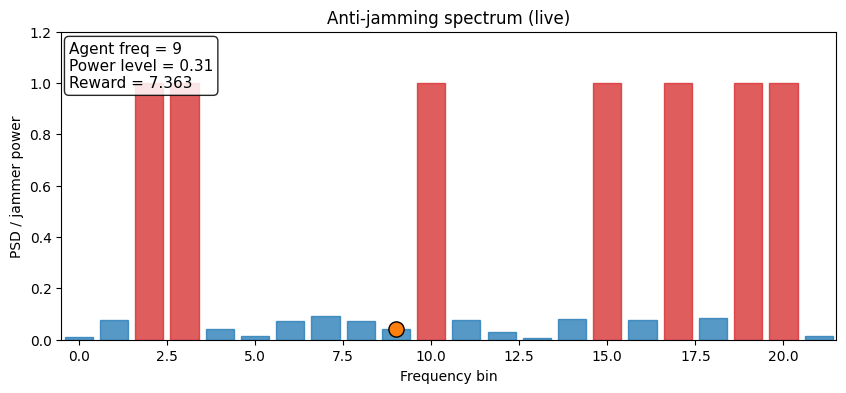

/var/folders/05/qn16crys2252lc2yqdc2ns_h0000gn/T/ipykernel_38879/540467237.py:188: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  self._last_reward = float(reward)


KeyboardInterrupt: 

In [41]:
import gymnasium as gym

# Create our training environment - a cart with a pole that needs balancing
env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=20)  # <-- K


# Reset environment to start a new episode
observation, info = env.reset()
# observation: what the agent can "see" - cart position, velocity, pole angle, etc.
# info: extra debugging information (usually not needed for basic learning)

print(f"Starting observation: {observation}")
# Example output: [ 0.01234567 -0.00987654  0.02345678  0.01456789]
# [cart_position, cart_velocity, pole_angle, pole_angular_velocity]

episode_over = False
total_reward = 0

while not episode_over:
    # Choose an action: 0 = push cart left, 1 = push cart right
    action = env.action_space.sample()  # Random action for now - real agents will be smarter!

    # Take the action and see what happens
    observation, reward, terminated, truncated, info = env.step(action)
    env.render()

    # reward: +1 for each step the pole stays upright
    # terminated: True if pole falls too far (agent failed)
    # truncated: True if we hit the time limit (500 steps)

    total_reward += reward
    episode_over = terminated or truncated

print(f"Episode finished! Total reward: {total_reward}")
env.close()

### instantiate env and agent (DQN) to learn for 200_000 steps

In [ ]:
from stable_baselines3 import DQN

env = gym.make('AntiJammingEnv-v0')
# env = AntiJammingEnv()
env = gym.wrappers.TimeLimit(env, max_episode_steps=20)  # <-- K


model = DQN("MlpPolicy", env, verbose=1)
model.learn(total_timesteps=100_000, log_interval=4)


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 20       |
|    ep_rew_mean      | 80       |
|    exploration_rate | 0.992    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 22995    |
|    time_elapsed     | 0        |
|    total_timesteps  | 80       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 20       |
|    ep_rew_mean      | 77.1     |
|    exploration_rate | 0.985    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 3614     |
|    time_elapsed     | 0        |
|    total_timesteps  | 160      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 2.21     |
|    n_updates        | 14       |
-------------------------------

/var/folders/05/qn16crys2252lc2yqdc2ns_h0000gn/T/ipykernel_38879/376620131.py:155: RuntimeWarning: invalid value encountered in log
  reward = crc_success * (np.log(1 + snr_for_reward) / power) - penalty


----------------------------------
| rollout/            |          |
|    ep_len_mean      | 20       |
|    ep_rew_mean      | nan      |
|    exploration_rate | 0.78     |
| time/               |          |
|    episodes         | 116      |
|    fps              | 2552     |
|    time_elapsed     | 0        |
|    total_timesteps  | 2320     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | nan      |
|    n_updates        | 554      |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 20       |
|    ep_rew_mean      | nan      |
|    exploration_rate | 0.772    |
| time/               |          |
|    episodes         | 120      |
|    fps              | 2553     |
|    time_elapsed     | 0        |
|    total_timesteps  | 2400     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | nan      |
|    n_updates      

### create a greedy policy (no RL in greedy, just to see if RL works)
decode action is a helper function to return freq and power from single action space of freq * power

In [3]:
import numpy as np

def decode_action(a, num_powers):
    freq = a // num_powers
    power = (a % num_powers) + 1
    return int(freq), int(power)

def greedy_policy(obs, num_powers, snr_thresh=1.5):
    # pick the least noisy freq (min PSD), then the smallest power that clears the threshold
    f = int(np.argmin(obs))
    for p in range(1, num_powers+1):
        snr = p / (float(obs[f]) + 1e-6)
        if snr > snr_thresh:
            return f * num_powers + (p - 1)
    return f * num_powers + (num_powers - 1)


In [4]:
def evaluate_agent(env, predict_fn, num_episodes=50, horizon=128, deterministic=True, name="agent"):
    returns = []
    success_rates = []
    switch_rates = []
    avg_powers = []
    jam_hit_rates = []  # how often we transmit on a jammed bin (≈ obs[f] > 0.9 in your env)

    for _ in range(num_episodes):
        obs, _ = env.reset()
        prev_freq = None
        total_r = 0.0
        success = 0
        switches = 0
        power_used = 0
        jam_hits = 0

        for t in range(horizon):
            # action from policy
            if name == "DQN":
                a, _ = predict_fn(obs, deterministic=deterministic) # DQN model chooses next action
            else:  # greedy baseline uses a function of obs
                a = predict_fn(obs)

            # step
            obs_next, r, terminated, truncated, info = env.step(int(a))
            total_r += float(r)

            # decode & compute metrics from obs_next (the env uses this for reward)
            freq, power = decode_action(int(a), env.num_powers)

            # Signal to noise ratio calculation (SNR) at chosen freq
            snr = power / (float(obs_next[freq]) + 1e-6)
            if snr > 1.5:
                success += 1

            if prev_freq is not None and prev_freq != freq:
                switches += 1

            # Penalize switching in reward calculation above
            prev_freq = freq

            power_used += power
            if obs_next[freq] > 0.9:  # jammed bin in this env is set to exactly 1.0
                jam_hits += 1

            if terminated or truncated:
                break

            obs = obs_next

        returns.append(total_r)
        success_rates.append(success / horizon)
        switch_rates.append(switches / horizon)
        avg_powers.append(power_used / horizon)
        jam_hit_rates.append(jam_hits / horizon)

    print(f"{name}: "
          f"return={np.mean(returns):.3f} "
          f"| success={np.mean(success_rates):.3f} "
          f"| switch_rate={np.mean(switch_rates):.3f} "
          f"| avg_power={np.mean(avg_powers):.2f} "
          f"| jam_hit_rate={np.mean(jam_hit_rates):.3f}")


In [5]:
# DQN (your trained model)
test_env = AntiJammingEnv()
evaluate_agent(test_env, model.predict, num_episodes=50, horizon=128, name="DQN")

# Greedy baseline
evaluate_agent(AntiJammingEnv(), lambda o: greedy_policy(o, num_powers=5), num_episodes=50, horizon=128, name="Greedy")


/var/folders/05/qn16crys2252lc2yqdc2ns_h0000gn/T/ipykernel_38879/2041143198.py:26: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  total_r += float(r)


DQN: return=708.710 | success=0.724 | switch_rate=0.000 | avg_power=1.00 | jam_hit_rate=0.276
Greedy: return=nan | success=0.965 | switch_rate=0.578 | avg_power=21.62 | jam_hit_rate=0.272


/var/folders/05/qn16crys2252lc2yqdc2ns_h0000gn/T/ipykernel_38879/376620131.py:155: RuntimeWarning: invalid value encountered in log
  reward = crc_success * (np.log(1 + snr_for_reward) / power) - penalty
